# SAE v3 — *following prior works* (Gao et al., 2024)

**Dissertação de mestrado (PPGCC/PUCRS).** Este notebook documenta a versão **final** do SAE
de domínio: por que refizemos, o que deu errado no caminho, o que mudou, e o que saiu —
comparado ao v1 (base dos resultados anteriores, ver `v1-historico/02-feature-discovery.ipynb`).

> Modelo: **Llama-3.1-8B-Instruct** (4-bit), camada 15 do *residual stream*. DeepSeek-R1-8B e
> Qwen3-8B seguem o mesmo protocolo (em andamento).

**Resumo (27/09/2026).**
- Treinamos o SAE em **todo** o VitaminC + FEVER: **598.930 claims → 132,4M token-ativações**
  (~12× o v1).
- O **primeiro treino v3** (com a otimização herdada do v1) **falhou**: as features mortas
  subiram a **48,6%**. Uma auditoria linha a linha contra o paper e o código oficial do
  **Gao et al. (2024)** mostrou que seguíamos a *arquitetura* dele, mas **não a *otimização***
  (Apêndice A).
- Com a otimização **alinhada ao Gao** (mantendo só o batch de 2.048, justificado pelo próprio
  §A.4), as features mortas caíram para **2 de 32.768 (0,006%)**, e o SAE ficou **melhor que o
  v1** em reconstrução da decisão e em localização da abstenção.
- A feature candidata agora é a **19219**: 93,5% dos 200 claims que mais a ativam são NEI
  (4,7×), e a taxa de NEI cresce monotonicamente com a intensidade da feature.


## 1. Por que um v3

O v1 funcionou (a abstenção se localizou na feature 22280), mas tinha duas fragilidades para
a dissertação:
1. **33% de features mortas** (10.830 de 32.768) — o dicionário efetivo era ~22k, e é o
   principal modo de falha de SAEs [Gao et al., 2024, §2.4].
2. **Pouco dado** (50k claims, ~11M tokens) e alguns hiperparâmetros ajustados *por nós*, sem
   referência — difícil de defender como *"following prior works"*.

**Objetivo do v3:** treinar com **todos os dados** e com a receita **de um trabalho de
referência**, para que cada escolha seja justificável por citação. Escolhemos o **Gao et al.
(2024)** — é a origem do TopK SAE que usamos desde o v1.


## 2. A jornada (com o que deu errado)

**(a) Harvest com todos os dados.** 598.930 claims (VitaminC 370.653 + FEVER 228.277; SUP
300.515 / REF 179.054 / NEI 119.361) renderizados no mesmo prompt de veredito do v1, um
*forward* por claim, resíduo da camada 15 em todas as posições → **132,4M token-ativações,
265 shards, 1.011 GB** (no HD de 4 TB). ~30 h de GPU.

**(b) Primeiro treino v3 — as features mortas explodiram.** Com a otimização herdada do v1
(lr 4e-4, perdas sem normalização), o treino mais longo (128.794 passos, ~12× o v1) **matava
features continuamente**: 0,2% no passo 10k → 26% no 20k → **48,6% no 35,9k** (gráfico na §4.1).
Paramos o treino e guardamos o checkpoint (`checkpoints/v3_llama_prealign`).

Um detalhe revelador: **no passo 10k — o tamanho do treino inteiro do v1 — esse SAE tinha só
0,2% de mortas.** Não era "mais dados piora"; era a otimização que não aguentava um treino longo.

**(c) Auditoria contra o Gao.** Lemos o paper (seções 2.1, 2.4, 3.1.2 e Apêndice A) e o
código oficial (`openai/sparse_autoencoder`). Resultado: seguíamos a **arquitetura e a perda**
(TopK, k, dicionário, AuxK), mas **não os detalhes de otimização** do Apêndice A — e não havia
registro de por quê, exceto o batch (reduzido pela GPU instável). Tabela completa na §3.

**(d) Alinhamento.** Implementamos cada item do Apêndice A como uma opção do `Config`
(desligada no v1, ligada no v3) e re-treinamos **reaproveitando o harvest** (só o treino,
~17 h). A §3.1 lista como validamos a implementação antes de rodar.

**Tropeços de infraestrutura (registrados por honestidade; não afetam os resultados):**
- **Segfaults aleatórios** eram do **Python 3.13 do Miniconda** (crash no próprio
  interpretador, em código puro da biblioteca padrão): 5/250 execuções vs 0/250 em dois
  Python 3.12, em teste intercalado. Migramos para um ambiente conda-forge com Python 3.12 e
  as **mesmas versões** de pacotes; as ativações produzidas são **idênticas bit a bit** às do
  ambiente antigo (1.163 tokens comparados, diferença 0,0), então os shards já gravados
  continuaram válidos.
- Houve também rajadas curtas de crash de GPU (mesmo sintoma do driver em 19/09), absorvidas
  pelo *resume* do treino.


## 3. Metodologia — o que seguimos do Gao et al. (2024)

| item | Gao et al. (2024) | v1 / 1º treino v3 | **v3 final** |
|---|---|---|---|
| arquitetura | TopK, k=32 (§2.3) | ✓ | ✓ |
| dicionário | 32.768 features | ✓ | ✓ |
| perda auxiliar | AuxK, α=1/32, k_aux=512 (§A.2) | ✓ | ✓ |
| limiar de "feature morta" | 10M tokens (nota 7, seguindo Templeton et al. 2024) | ~2M | ✓ (5.000 passos × 2.048) |
| init do encoder | transposta do decoder (§A.1) | ✓ | ✓ |
| decoder com norma unitária | após cada passo (§A.1) | ✓ | ✓ |
| **normalização da entrada** | tira a média em d_model e normaliza à norma 1 (§2.1; motivação no §B) | ✗ | ✓ |
| **MSE principal normalizado** | constante calculada 1× no início (§A.6) | ✗ | ✓ |
| **AuxK normalizada** | pela escala do resíduo (§A.6; `normalized_mse` do código oficial) | ✗ | ✓ |
| **Adam ε** | 6,25×10⁻¹⁰ (§A.3.1) | 10⁻⁸ | ✓ |
| **projeção do gradiente do decoder** | remove a componente paralela (§A.3, seguindo Bricken et al. 2023) | ✗ | ✓ |
| **b_pre** | mediana geométrica de uma amostra (§A.1, seguindo Bricken et al. 2023) | média | ✓ |
| **EMA dos pesos** | 0,999 (§A.5) | ✗ | ✓ |
| **learning rate** | varrido; máximo ∝ 1/√n (§3.1.2); código oficial: 1e-4 p/ n=32.768 | 4e-4 | **1e-4** |
| batch | 131.072 tokens (§A.4) | 2.048 | **2.048** (única divergência) |

**Por que o batch de 2.048 é defensável.** O próprio §A.4 registra que *"prior work tends to
use batch sizes like 2048 or 4096 tokens [Bricken et al. 2023; Conerly et al. 2024;
Rajamanoharan et al. 2024]"* e que a perda na convergência *"does not depend strongly on batch
size when optimization hyperparameters are set appropriately"* (Fig. 12). Além disso, 131k
tokens × 4.096 dims não cabe na GPU de 16 GB.

**Duas notas de fidelidade.**
- O texto do §A.6 diz que a AuxK é normalizada *"per token"*; o código oficial normaliza pela
  variância **do lote** (`normalized_mse`). Seguimos o **código** de referência.
- O lr de 1e-4 é o padrão do código oficial para 32.768 features; não re-varremos o lr para o
  nosso batch. A nota 16 do paper (*"lowering learning rates helped with decreasing dead
  latents"*) vai na mesma direção da nossa troca 4e-4 → 1e-4.

**Nota sobre a normalização da entrada.** Com ela, o SAE opera no espaço centrado e de norma 1.
As análises (FVU, cosseno) convertem de volta para o espaço bruto quando comparam com o v1.


### 3.1 Como validamos a implementação antes de rodar

- **v1 não mudou:** com as opções desligadas, o código novo gera um SAE **idêntico bit a bit**
  ao do código antigo (mesmos dados, mesma semente).
- **AuxK normalizada = fórmula do código oficial** (diferença 0,0 num lote de teste).
- **Projeção do gradiente:** gradiente resultante ortogonal a cada direção do decoder
  (|⟨g, w⟩| ≈ 10⁻¹¹).
- **Resume:** matamos o treino no meio; ele retomou com a EMA e a constante do MSE restauradas.
- **Análise:** o FVU na decisão foi recalculado de forma independente em torch e bateu com o
  `abstention.py`.


## 4. Resultados

In [1]:
import json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

R = "../results"
def load(p):
    return json.load(open(p, encoding="utf-8"))

cur  = load(f"{R}/v3_llama/train_curves.json")
v3a  = load(f"{R}/v3_llama/abstention.json")
v3m  = load(f"{R}/v3_llama/train_metrics.json")
v3f  = load(f"{R}/v3_llama/feature_19219_examples.json")
v3h  = load(f"{R}/v3_llama/feature_19219_hist.json")
v1a  = load(f"{R}/v1_domain/abstention.json")
v1m  = load("../checkpoints/v1_domain/metrics.json")
v1f  = load(f"{R}/v1_domain/feature_22280_examples.json")
W = cur["width"]
print("artefatos carregados")

artefatos carregados


### 4.1 Features mortas: o efeito do alinhamento

**Como ler este gráfico.** O eixo **X** é o passo de treino (cada passo = 2.048 tokens); o
eixo **Y** é a porcentagem das 32.768 features que estão **mortas** (não dispararam nos
últimos 5.000 passos ≈ 10M tokens — por isso a curva só "liga" depois do passo 5.000). Em
**vermelho**, o 1º treino v3 (otimização herdada do v1), interrompido no passo 35.900; em
**azul**, o treino alinhado ao Gao. A linha pontilhada cinza marca os **7%** que o Gao reporta
para o seu maior SAE (§2.4); o **losango preto** marca o v1 ao fim do seu treino (33%, com um
limiar de morte mais curto, ~2M tokens).

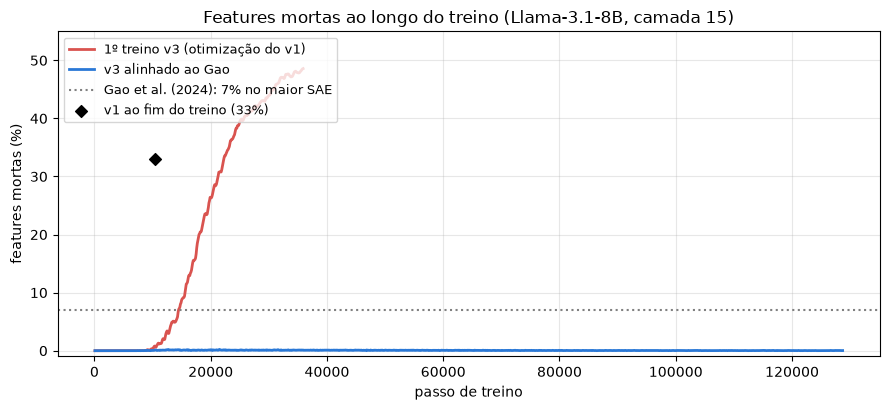

1º treino v3 no passo 35900: 15919 mortas (48.6%)
v3 alinhado ao final (128794 passos): 2 mortas (0.006%)


In [2]:
pre = np.array(cur["prealign"]); ali = np.array(cur["aligned"])
fig, ax = plt.subplots(figsize=(9, 4.2))
ax.plot(pre[:, 0], 100 * pre[:, 2] / W, color="#d9534f", lw=2, label="1º treino v3 (otimização do v1)")
ax.plot(ali[:, 0], 100 * ali[:, 2] / W, color="#2a78d6", lw=2, label="v3 alinhado ao Gao")
ax.axhline(7, color="gray", ls=":", lw=1.5, label="Gao et al. (2024): 7% no maior SAE")
ax.scatter([v1m["steps"]], [100 * v1m["dead_features"] / W], marker="D", color="black", zorder=5,
           label=f"v1 ao fim do treino ({100*v1m['dead_features']/W:.0f}%)")
ax.set_xlabel("passo de treino"); ax.set_ylabel("features mortas (%)")
ax.set_ylim(-1, 55); ax.legend(loc="upper left", fontsize=9); ax.grid(alpha=.3)
ax.set_title("Features mortas ao longo do treino (Llama-3.1-8B, camada 15)")
plt.tight_layout(); plt.show()
print(f"1º treino v3 no passo {int(pre[-1,0])}: {int(pre[-1,2])} mortas ({100*pre[-1,2]/W:.1f}%)")
print(f"v3 alinhado ao final ({v3m['steps']} passos): {v3m['dead_features']} mortas ({100*v3m['dead_features']/W:.3f}%)")

👉 **Leitura.** O alinhamento resolveu o principal defeito do dicionário. No treino alinhado,
a contagem de mortas **oscila perto de zero** (features que param são reanimadas pela AuxK) e
**cai** no fim (~10 → 2), enquanto no treino anterior ela só subia. Ficamos **bem abaixo** dos
7% do Gao — com a ressalva de que o SAE dele é muito maior (16M features).

### 4.2 v1 × v3: reconstrução e localização da abstenção

**O que cada linha mede** (mesmas definições do `v1-historico/02-feature-discovery.ipynb`):
- **FVU na decisão** — erro de reconstrução na posição da decisão, denominador = variância
  *entre* as decisões, **no espaço bruto** (comparável ao v1). Menor = melhor.
- **max cos** — cosseno entre a direção de abstenção (diff-of-means) e a feature mais alinhada
  do decoder. Maior = abstenção mais localizada numa feature.
- **cos da 2ª feature** — quão isolada é a 1ª (menor = mais isolada).
- **AUC da direção** — separação NEI × SUP/REF pela direção densa, **no resíduo bruto, sem
  SAE** (held-out par/ímpar).

In [3]:
rows = [
  ("claims (decisões)",            v1a["n_decision"],                 v3a["n_decision"]),
  ("features mortas",              f"{v1m['dead_features']} ({100*v1m['dead_features']/W:.0f}%)",
                                   f"{v3m['dead_features']} ({100*v3m['dead_features']/W:.3f}%)"),
  ("FVU na decisão (bruto) ↓",     round(v1a["fvu_decision_domainSAE"], 3), round(v3a["fvu_decision_domainSAE"], 3)),
  ("max cos(direção, feature) ↑",  round(v1a["max_decoder_cos"], 3),        round(v3a["max_decoder_cos"], 3)),
  ("cos da 2ª feature ↓",          round(v1a["top_decoder_cos"][1]["cos"], 3), round(v3a["top_decoder_cos"][1]["cos"], 3)),
  ("feature candidata",            v1a["top_decoder_cos"][0]["feat"],      v3a["top_decoder_cos"][0]["feat"]),
  ("max |Cohen's d|",              round(v1a["max_abs_cohens_d_feature"], 2), round(v3a["max_abs_cohens_d_feature"], 2)),
  ("AUC da direção (sem SAE)",     round(v1a["auc_direction_heldout"], 3),  round(v3a["auc_direction_heldout"], 3)),
]
pd.DataFrame(rows, columns=["métrica", "v1", "v3 (Gao)"]).set_index("métrica")

,v1,v3 (Gao)
métrica,,
claims (decisões),50000,598930
features mortas,10830 (33%),2 (0.006%)
FVU na decisão (bruto) ↓,0.294,0.234
"max cos(direção, feature) ↑",0.673,0.716
cos da 2ª feature ↓,0.487,0.38
feature candidata,22280,19219
max |Cohen's d|,1.33,1.28
AUC da direção (sem SAE),0.839,0.796


👉 **Leitura.**
- O v3 **reconstrói melhor a decisão** (0,294 → 0,234) e **localiza melhor a abstenção** numa
  feature (cos 0,673 → 0,716), com a feature candidata **mais isolada** (a 2ª cai de 0,49 para
  0,38).
- A **mesma feature** lidera em cosseno **e** em Cohen's d — no v1 também (22280); no v3 é a
  **19219**. Ou seja, o achado central do v1 se **replica** com um SAE melhor e mais dados.
- A **AUC da direção caiu** (0,839 → 0,796), mas ela **não depende do SAE**: é calculada no
  resíduo bruto. O que mudou foi o **conjunto de dados** (50k → 598.930 claims). Com o
  VitaminC + FEVER completos, separar NEI de SUP/REF linearmente é mais difícil. Deve ser
  reportado assim no texto.

### 4.3 A feature 19219: validação semântica

**Método.** Diferente do v1 (6.000 claims re-passados pelo modelo, ativação aproximada por
`relu(pré-ativação)`), aqui usamos as ativações **já cacheadas de todas as 598.930 decisões**
e a ativação **real** da feature (normalização da entrada + TopK, como no treino). Antes,
conferimos o alinhamento texto ↔ ativação: rótulo e fonte de cada decisão batem com a linha
correspondente do `examples.jsonl` em **100%** dos casos.

**Como ler este gráfico.** *Esquerda:* histograma da ativação da feature 19219 na posição da
decisão (eixo X = ativação; eixo Y = fração dos claims de cada grupo, para comparar grupos de
tamanhos diferentes), NEI em laranja e SUP/REF em azul. *Direita:* os claims são divididos em
**10 faixas iguais (decis) de ativação** (eixo X, da menor para a maior); o eixo Y é a
**porcentagem de NEI** em cada faixa; a linha tracejada é a taxa geral de NEI (19,9%).

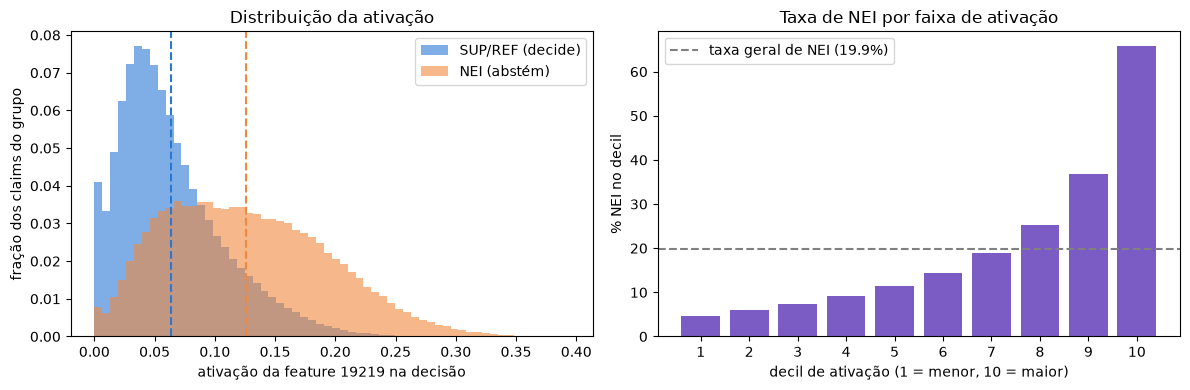

média NEI = 0.126 | média SUP/REF = 0.064 | claims com ativação 0 = 2.9%
NEI por decil: 5% → 6% → 7% → 9% → 11% → 14% → 19% → 25% → 37% → 66%


In [4]:
b = np.array(v3h["bins"]); c = (b[:-1] + b[1:]) / 2
hn = np.array(v3h["hist_nei"]) / v3h["n_nei"]; hd = np.array(v3h["hist_dec"]) / v3h["n_dec"]
dec = np.array([d[2] for d in v3h["nei_rate_by_decile"]])
fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.bar(c, hd, width=b[1]-b[0], color="#2a78d6", alpha=.6, label="SUP/REF (decide)")
a1.bar(c, hn, width=b[1]-b[0], color="#f0883e", alpha=.6, label="NEI (abstém)")
a1.axvline(v3h["mean_dec"], color="#2a78d6", ls="--"); a1.axvline(v3h["mean_nei"], color="#f0883e", ls="--")
a1.set_xlabel("ativação da feature 19219 na decisão"); a1.set_ylabel("fração dos claims do grupo")
a1.legend(); a1.set_title("Distribuição da ativação")
a2.bar(range(1, 11), 100 * dec, color="#7a5cc4")
a2.axhline(100 * v3h["nei_base"], color="gray", ls="--", label=f"taxa geral de NEI ({100*v3h['nei_base']:.1f}%)")
a2.set_xlabel("decil de ativação (1 = menor, 10 = maior)"); a2.set_ylabel("% NEI no decil")
a2.set_xticks(range(1, 11)); a2.legend(); a2.set_title("Taxa de NEI por faixa de ativação")
plt.tight_layout(); plt.show()
print(f"média NEI = {v3h['mean_nei']:.3f} | média SUP/REF = {v3h['mean_dec']:.3f} | "
      f"claims com ativação 0 = {100*v3h['frac_zero']:.1f}%")
print("NEI por decil:", " → ".join(f"{100*x:.0f}%" for x in dec))

In [5]:
sel = pd.DataFrame([
  ("top-50",   v3f["nei_top50"],   v3f["enrich_top50"]),
  ("top-200",  v3f["nei_top200"],  v3f["enrich_top200"]),
  ("top-1000", v3f["nei_top1000"], v3f["enrich_top1000"]),
], columns=["claims que mais ativam", "% NEI", "enriquecimento"])
sel["% NEI"] = (100 * sel["% NEI"]).round(1); sel["enriquecimento"] = sel["enriquecimento"].round(1).astype(str) + "×"
src = pd.DataFrame([(k, v["n"], round(100*v["nei_base"], 1), round(100*v["nei_top200"], 1), round(v["auc_feature_topk"], 3))
                    for k, v in v3f["by_source"].items()],
                   columns=["fonte", "claims", "% NEI geral", "% NEI no top-200", "AUC da feature"])
display(sel.set_index("claims que mais ativam")); display(src.set_index("fonte"))
print(f"AUC da feature (todas as decisões) = {v3f['auc_feature_topk']:.3f} | "
      f"v1 (22280): {100*v1f['nei_top200']:.0f}% NEI no top-200, numa amostra de {v1f['n_seen']} claims")

,% NEI,enriquecimento
claims que mais ativam,,
top-50,88.0,4.4×
top-200,93.5,4.7×
top-1000,95.8,4.8×


,claims,% NEI geral,% NEI no top-200,AUC da feature
fonte,,,,
vitaminc,370653,14.3,77.5,0.716
fever,228277,29.1,99.0,0.843


AUC da feature (todas as decisões) = 0.783 | v1 (22280): 61% NEI no top-200, numa amostra de 6000 claims


In [6]:
top = pd.DataFrame([(t["rank"], round(t["act"], 3), t["label"], t["source"], t["claim"]) for t in v3f["top"][:20]],
                   columns=["#", "ativação", "rótulo", "fonte", "claim"]).set_index("#")
pd.set_option("display.max_colwidth", 120); top

,ativação,rótulo,fonte,claim
#,,,,
1,0.394,NEI,fever,Cosmopolitan changed its subject matter.
2,0.390,NEI,fever,Gunday is a bad film.
3,0.387,NEI,fever,The Host stars an actress that gave birth on April 12.
4,0.386,NEI,fever,The Democratic Party has more money than the Republican Party.
5,0.385,NEI,fever,The Host stars an actress that gave birth on July 15.
6,0.385,NEI,vitaminc,Boneykapoor is a producer .
7,0.384,NEI,fever,"The Democratic Party has more 20,000 members than the Republican Party."
8,0.383,NEI,fever,The Host stars an actress born on June 12.
9,0.380,NEI,fever,Gunday is a bad film.


👉 **Leitura.**
- **Seletividade alta:** 93,5% dos 200 claims que mais ativam a 19219 são NEI (4,7× a taxa
  geral); 95,8% no top-1000. No v1, a 22280 tinha 61% no top-200 — mas numa amostra de 6.000
  claims e com ativação aproximada, então a comparação é só indicativa.
- **Semântica coerente com abstenção:** os claims do topo são afirmações que **não dá para
  verificar com a evidência dada** — trivialidades sobre pessoas (*"The Host stars an actress
  that gave birth on April 12"*), juízos subjetivos (*"Gunday is a bad film"*), comparações
  sem base (*"The Democratic Party has more money than the Republican Party"*). É o mesmo
  perfil da 22280 do v1.
- **Mais forte no FEVER** (99% NEI no top-200, AUC 0,84) que no VitaminC (77,5%, AUC 0,72).
- **Não é uma feature liga/desliga:** ela está ativa em **97%** das decisões; o que codifica a
  abstenção é a **intensidade** (média em NEI ≈ 2× a média em SUP/REF). O gráfico de decis
  mostra que a relação é **monotônica**: a taxa de NEI sobe de ~5% na faixa mais baixa para
  ~66% na mais alta.

## 5. Discussão, limitações e próximos passos

**O que o v3 estabelece.** Com uma receita de treino **citável** (Gao et al., 2024, com uma
única divergência justificada), o SAE de domínio tem um dicionário praticamente sem features
mortas, reconstrói melhor a posição da decisão e localiza a abstenção numa feature mais
isolada e mais seletiva do que o v1. O achado do v1 se **replica**.

**Limitações (para o texto):**
1. **A 19219 é graduada, não binária.** Ativa em 97% das decisões; a abstenção está na
   magnitude. Falta checar quanto ela ativa **fora** da posição de decisão (tokens de claim e
   evidência) — isso separa "feature da decisão modulada por abstenção" de "feature de
   posição".
2. **AUC da direção menor** (0,796) com o conjunto completo de dados — efeito dos dados, não
   do SAE.
3. **Espaços diferentes:** o FVU do log de treino é no espaço normalizado; o FVU na decisão
   comparável ao v1 é recalculado no espaço bruto.
4. **Batch e lr:** batch 2.048 (justificado pelo §A.4) e lr 1e-4 sem nova varredura.
5. **Uma rodada só** (sem sementes múltiplas).
6. **Só o Llama até aqui.** DeepSeek (harvest pausado em 44.499/598.930) e Qwen3 seguem o mesmo
   protocolo; depois, Gemma3, Gemma4, Mistral e Ministral.

**Próximos passos.** (i) Steering com a feature 19219 no fatorial Single/Iterative ×
{com, sem evidência} × {aumentar, diminuir} (ver `v1-historico/05-steering-factcheck.ipynb`); (ii) refazer
generalização e cross-model no v3; (iii) exportar para o HuggingFace/Neuronpedia.


## 6. Export para publicação (formato SAELens)

**Por quê SAELens:** é o formato padrão da área para SAEs abertos — qualquer pessoa carrega o SAE com
`SAE.load_from_disk(...)` (ou `SAE.from_pretrained(...)` do HuggingFace Hub), e é o formato que o
Neuronpedia aceita para os dashboards das features.

**Onde:** `/mnt/d/Projetos WSL/fact-checking-abstention-saes/llama-3.1-8b-instruct/layer-15/` — `cfg.json`,
`sae_weights.safetensors`, `README.md` (model card, em inglês), `fcsae_training_config.json`,
`export_verification.json`. Código: `fcsae/export/to_saelens.py`.

**A normalização da entrada.** Nosso SAE opera em $x_n = (x-\mu)/\lVert x-\mu \rVert$ (§3). O SAELens tem
`normalize_activations="layer_norm"`: $x_{ln} = (x-\mu)/(\sigma+\epsilon)$ com
$\sigma = \lVert x-\mu \rVert/\sqrt{d-1}$, ou seja, $x_{ln} \approx c\,x_n$ com $c = \sqrt{d-1} \approx 64$.
Exportamos os pesos reescalados ($W_{enc}/c$, $b_{dec}\cdot c$, $W_{dec}\cdot c$; $b_{enc}$ igual): a
pré-ativação e as features ativas ficam as mesmas, e a reconstrução no espaço bruto também.

**Verificação (20.000 decisões reais do harvest, nosso SAE × SAELens recarregado do disco):**

| | resultado |
|---|---|
| FVU da reconstrução | 0,27800 × 0,27800 (idêntico até a 5ª casa) |
| feature 19219 | correlação 0,999999; diferença máxima 3 × 10⁻⁵ |
| conjunto das 32 features ativas | idêntico em 99,885% das decisões |
| … reproduzindo o SAELens **sem** o seu ε = 10⁻⁵ | idêntico em **100%** |

A pequena diferença vem **só** do ε que o SAELens soma ao desvio padrão (≈ 0,008% do tamanho típico
do resíduo): nos ~0,1% dos tokens em que a 32ª e a 33ª pré-ativação estão praticamente empatadas, ele
troca uma feature. Isso está registrado no model card.

**Publicado (privado) no HuggingFace em 28/09/2026:**
- SAEs: `lucasfrag/fact-checking-abstention-saes` → `llama-3.1-8b-instruct/layer-15/`
- dados: `lucasfrag/fact-checking-abstention-saes-data` → `llama-3.1-8b-instruct/examples.jsonl` e
  `decisions.safetensors`

**Verificação a partir do Hub** (download numa pasta limpa):
- os 7 arquivos são **idênticos byte a byte** aos locais (SHA-256);
- com o SAE e as ativações **baixados**, carregando pelo SAELens:

| métrica | a partir do Hub | local |
|---|---|---|
| AUC da feature 19219 | 0,78284 | 0,78296 |
| % NEI no top-200 da 19219 | 93,5% | 93,5% |
| FVU na decisão (espaço bruto) | 0,23363 | 0,23363 |
| fração de decisões com a 19219 ativa | 97,06% | 97,06% |

(a diferença de 10⁻⁴ na AUC é o ε do SAELens, acima.)

**Pendente antes de tornar público:** conferir as licenças (Llama 3.1, VitaminC, FEVER).


## Referências

- **Arditi, A., et al. (2024).** Refusal in Language Models Is Mediated by a Single Direction. *NeurIPS 2024. arXiv:2406.11717.*
- **Bricken, T., et al. (2023).** Towards Monosemanticity: Decomposing Language Models With Dictionary Learning. *Transformer Circuits (Anthropic).*
- **Conerly, T., et al. (2024).** Update on how we train SAEs. *Transformer Circuits Thread.*
- **Gao, L., et al. (2024).** Scaling and Evaluating Sparse Autoencoders. *arXiv:2406.04093.* Código: `github.com/openai/sparse_autoencoder`.
- **He, Z., et al. (2024).** Llama Scope: Extracting Millions of Features from Llama-3.1-8B. *arXiv:2410.20526.*
- **Rajamanoharan, S., et al. (2024).** Improving Dictionary Learning with Gated Sparse Autoencoders. *arXiv:2404.16014.*
- **Schuster, T., et al. (2021).** Get Your Vitamin C! … (VitaminC). *NAACL 2021.*
- **Templeton, A., et al. (2024).** Scaling Monosemanticity … Claude 3 Sonnet. *Transformer Circuits (Anthropic).*
- **Thorne, J., et al. (2018).** FEVER: a Large-scale Dataset for Fact Extraction and VERification. *NAACL 2018.*
